**Food Delivery Time Prediction**


In [1]:
import pandas as pd
df=pd.read_csv("/Users/paarthrana/Desktop/summer 2026/delivery-time-prediction/data/Food_Delivery_Time_Prediction.csv")

DATA PREPROCESSING

In [2]:
df.head()

,Order_ID,Customer_Location,Restaurant_Location,Distance,Weather_Conditions,Traffic_Conditions,Delivery_Person_Experience,Order_Priority,Order_Time,Vehicle_Type,Restaurant_Rating,Customer_Rating,Delivery_Time,Order_Cost,Tip_Amount
0,ORD0001,"(17.030479, 79.743077)","(12.358515, 85.100083)",1.57,Rainy,Medium,4,Medium,Afternoon,Car,4.1,3.0,26.22,1321.10,81.54
1,ORD0002,"(15.398319, 86.639122)","(14.174874, 77.025606)",21.32,Cloudy,Medium,8,Low,Night,Car,4.5,4.2,62.61,152.21,29.02
2,ORD0003,"(15.687342, 83.888808)","(19.594748, 82.048482)",6.95,Snowy,Medium,9,High,Night,Bike,3.3,3.4,48.43,1644.38,64.17
3,ORD0004,"(20.415599, 78.046984)","(16.915906, 78.278698)",13.79,Cloudy,Low,2,Medium,Evening,Bike,3.2,3.7,111.63,541.25,79.23
4,ORD0005,"(14.786904, 78.706532)","(15.206038, 86.203182)",6.72,Rainy,High,6,Low,Night,Bike,3.5,2.8,32.38,619.81,2.34


In [3]:
df.shape

(200, 15)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 15 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Order_ID                    200 non-null    str    
 1   Customer_Location           200 non-null    str    
 2   Restaurant_Location         200 non-null    str    
 3   Distance                    200 non-null    float64
 4   Weather_Conditions          200 non-null    str    
 5   Traffic_Conditions          200 non-null    str    
 6   Delivery_Person_Experience  200 non-null    int64  
 7   Order_Priority              200 non-null    str    
 8   Order_Time                  200 non-null    str    
 9   Vehicle_Type                200 non-null    str    
 10  Restaurant_Rating           200 non-null    float64
 11  Customer_Rating             200 non-null    float64
 12  Delivery_Time               200 non-null    float64
 13  Order_Cost                  200 non-null    fl

In [5]:
df.isnull().sum()

Order_ID                      0
Customer_Location             0
Restaurant_Location           0
Distance                      0
Weather_Conditions            0
Traffic_Conditions            0
Delivery_Person_Experience    0
Order_Priority                0
Order_Time                    0
Vehicle_Type                  0
Restaurant_Rating             0
Customer_Rating               0
Delivery_Time                 0
Order_Cost                    0
Tip_Amount                    0
dtype: int64

In [6]:
df.duplicated().sum()


np.int64(0)

In [9]:
print("Customer locations:", df["Customer_Location"].nunique())
print("Restaurant locations:", df["Restaurant_Location"].nunique())

print(df["Customer_Location"].value_counts())
print(df["Restaurant_Location"].value_counts())

Customer locations: 200
Restaurant locations: 200
Customer_Location
(17.030479, 79.743077)    1
(15.398319, 86.639122)    1
(15.687342, 83.888808)    1
(20.415599, 78.046984)    1
(14.786904, 78.706532)    1
                         ..
(17.910045, 81.56199)     1
(21.66459, 82.226635)     1
(14.575401, 82.55641)     1
(12.094497, 82.893369)    1
(19.360304, 84.132424)    1
Name: count, Length: 200, dtype: int64
Restaurant_Location
(12.358515, 85.100083)    1
(14.174874, 77.025606)    1
(19.594748, 82.048482)    1
(16.915906, 78.278698)    1
(15.206038, 86.203182)    1
                         ..
(18.098924, 87.896124)    1
(16.892341, 80.554716)    1
(13.625369, 82.418092)    1
(19.135509, 86.659978)    1
(20.941636, 77.01334)     1
Name: count, Length: 200, dtype: int64


In [10]:
print(df["Order_Time"].head(10))
print(df["Order_Time"].unique())

0    Afternoon
1        Night
2        Night
3      Evening
4        Night
5      Evening
6      Evening
7      Evening
8        Night
9    Afternoon
Name: Order_Time, dtype: str
<StringArray>
['Afternoon', 'Night', 'Evening', 'Morning']
Length: 4, dtype: str


In [12]:
categorical_cols = [
    "Weather_Conditions",
    "Traffic_Conditions",
    "Order_Priority",
    "Vehicle_Type"
]
for col in categorical_cols:
    print("\n",col)
    print(df[col].unique())


 Weather_Conditions
<StringArray>
['Rainy', 'Cloudy', 'Snowy', 'Sunny']
Length: 4, dtype: str

 Traffic_Conditions
<StringArray>
['Medium', 'Low', 'High']
Length: 3, dtype: str

 Order_Priority
<StringArray>
['Medium', 'Low', 'High']
Length: 3, dtype: str

 Vehicle_Type
<StringArray>
['Car', 'Bike', 'Bicycle']
Length: 3, dtype: str


In [16]:
df["Delivery_Time"].describe()

count    200.000000
mean      70.494950
std       29.830694
min       15.230000
25%       46.997500
50%       72.775000
75%       96.650000
max      119.670000
Name: Delivery_Time, dtype: float64

In [15]:
print(df["Delivery_Time"].describe())

print("Median:", df["Delivery_Time"].median())
print("Mode:", df["Delivery_Time"].mode()[0])
print("Variance:", df["Delivery_Time"].var())

count    200.000000
mean      70.494950
std       29.830694
min       15.230000
25%       46.997500
50%       72.775000
75%       96.650000
max      119.670000
Name: Delivery_Time, dtype: float64
Median: 72.775
Mode: 66.84
Variance: 889.8703226105528


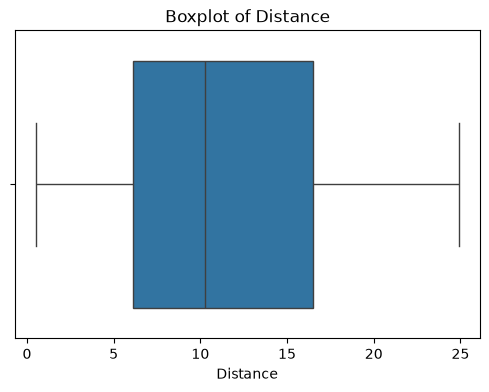

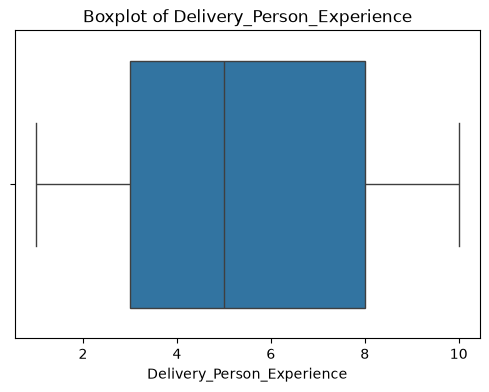

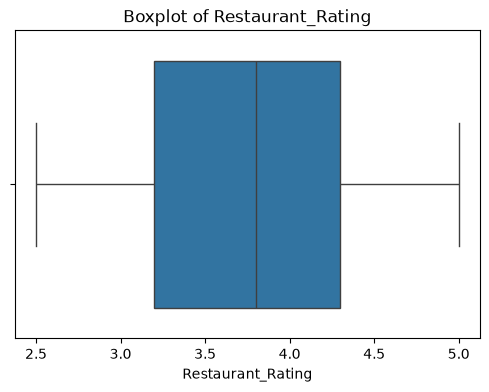

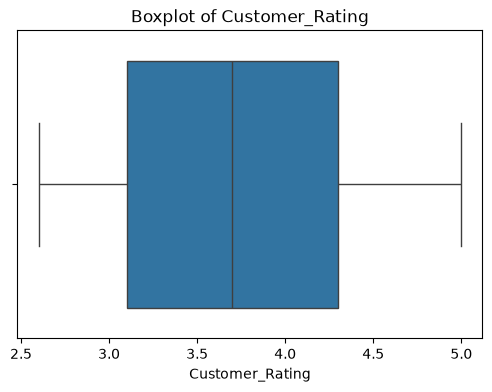

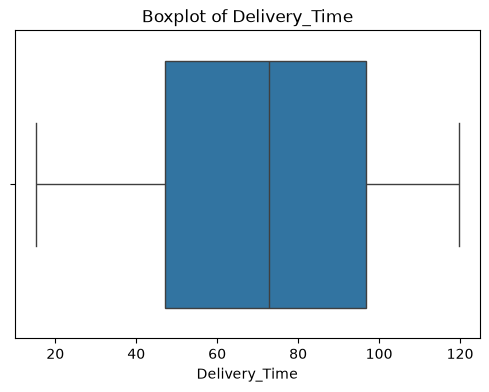

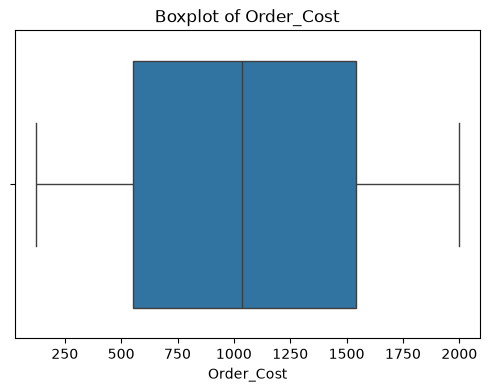

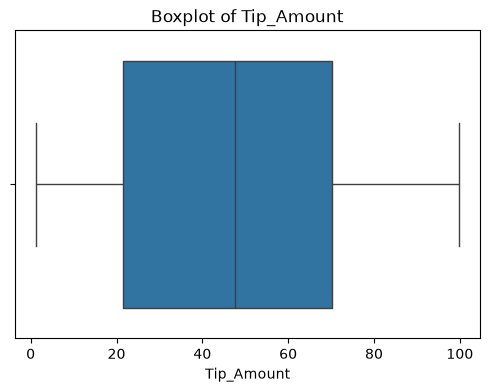

In [17]:

import matplotlib.pyplot as plt
import seaborn as sns

numerical_cols = [
    "Distance",
    "Delivery_Person_Experience",
    "Restaurant_Rating",
    "Customer_Rating",
    "Delivery_Time",
    "Order_Cost",
    "Tip_Amount"
]

for col in numerical_cols:
    plt.figure(figsize=(6, 4))
    sns.boxplot(x=df[col])
    plt.title(f"Boxplot of {col}")
    plt.show()


In [19]:
df[numerical_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
Distance,200.0,11.49805,6.841755,0.52,6.0900,10.265,16.4975,24.90
Delivery_Person_Experience,200.0,5.25000,2.745027,1.00,3.0000,5.000,8.0000,10.00
Restaurant_Rating,200.0,3.73850,0.703021,2.50,3.2000,3.800,4.3000,5.00
Customer_Rating,200.0,3.68650,0.697063,2.60,3.1000,3.700,4.3000,5.00
Delivery_Time,200.0,70.49495,29.830694,15.23,46.9975,72.775,96.6500,119.67
Order_Cost,200.0,1046.48870,548.568922,122.30,553.2700,1035.950,1543.1250,1997.42
Tip_Amount,200.0,46.61665,29.361706,1.24,21.6025,47.530,70.2450,99.74
